# 5. Writing your own components

Everything in a scenario is looked up in the registry, so a new power-control rule, attack or
defence is a small class plus a decorator. It then works by name everywhere: in Python, in
YAML configs and on the command line. This notebook adds one of each.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import aircompkit as ac

print("AirCompKit", ac.__version__)

AirCompKit 1.0.0


In [2]:
from dataclasses import dataclass
from aircompkit import register

## A power-control rule

A power-control component is called with the effective channel gains `g [T, K]`, large-scale
gains `beta [K]`, power budgets `p_max [K]` and the noise variance, and returns transmit powers
`p [T, K]` and the receive scaling `eta [T]`. The rule below schedules only the `n_best`
strongest devices and inverts their channels. `Scenario.design` checks every component against
the power budgets.

In [3]:
@register("power_control", "best_n_inversion")
@dataclass
class BestNInversion:
    n_best: int = 10

    def __call__(self, g, beta, p_max, noise_var):
        rank = np.argsort(-g, axis=1)
        on = np.zeros_like(g, bool)
        np.put_along_axis(on, rank[:, : self.n_best], True, axis=1)
        eta = np.min(np.where(on, p_max[None, :] * g, np.inf), axis=1)
        p = np.where(on, eta[:, None] / np.where(g > 0, g, 1), 0.0)
        return p, eta

base = dict(devices={"name": "fixed", "K": 20, "p_max": 10.0}, channel="rayleigh",
            target="sum", noise_var=1.0, seed=0)
for pc in ("channel_inversion", {"name": "best_n_inversion", "n_best": 15},
           {"name": "best_n_inversion", "n_best": 10}, "optimal"):
    r = ac.Scenario(**base, power_control=pc).run(trials=2000, dim=16)
    print(f"{str(pc):45s} median MSE {np.median(r['mse']):8.4g}  active {r['n_active'].mean():.1f}")

channel_inversion                             median MSE      1.5  active 20.0
{'name': 'best_n_inversion', 'n_best': 15}    median MSE    5.157  active 15.0
{'name': 'best_n_inversion', 'n_best': 10}    median MSE    10.07  active 10.0
optimal                                       median MSE   0.6954  active 20.0


Scheduling fewer devices raises $\eta$ and so cuts the noise term, but the excluded devices'
values are missing from the sum. For a sum target that bias dominates here, and the rule loses to
plain channel inversion; the MSE accounts for both terms.

## An attack

Attacks subclass `aircompkit.adversary.Attack`. `transmit(x, b, ctx)` returns what the attacker
rows send, given their unit-power symbols `x [n, L]` and the AirComp pre-equalisers `b [n]`.
`needs` declares the knowledge the attack uses (here only its own data, the default). This one
ignores its update and pushes the model along one fixed random direction:

In [4]:
from aircompkit.adversary import Attack

@register("attack", "fixed_bias")
@dataclass
class FixedBias(Attack):
    seed: int = 0   # the same direction every round, so the bias accumulates in the model

    def transmit(self, x, b, ctx):
        L = x.shape[1]
        rng = np.random.default_rng(self.seed)
        v = (rng.standard_normal(L) + 1j * rng.standard_normal(L)) / np.sqrt(2)
        return self.gain * v[None, :] * b[:, None]

## A defence

A defence has `reset(K)` and `aggregate(rx, ctx)`. `rx.transmit(ids)` performs one AirComp
channel use and returns the received block `Y [N, L]`, the signatures `A = H B` (`[N, K]`), `eta`,
the design combiner `m` and the noise variance. The defence returns an estimate of the honest sum,
the effective number of devices in it, and the set it excluded. This one is a simple detector:
it applies a matched filter to every device's signature, flags devices whose energy exceeds
`kappa` times the median, and removes them with a null-steering combiner. Its `detect` method
also makes it usable for detection Monte Carlo (below).

In [5]:
from aircompkit.defense import nulling_combiner

@register("defense", "mf_nulling")
@dataclass
class MatchedFilterNulling:
    kappa: float = 4.0

    def detect(self, Y, A, noise_var):
        e = np.mean(np.abs(A.conj().T @ Y) ** 2, axis=1) / np.sum(np.abs(A) ** 2, axis=0) ** 2
        return [int(k) for k in np.flatnonzero(e > self.kappa * np.median(e))]

    def reset(self, K):
        pass

    def aggregate(self, rx, ctx):
        r = rx.transmit()
        flagged = set(self.detect(r.Y, r.A, r.noise_var))
        w, keep = nulling_combiner(r.A, sorted(flagged), r.eta, r.noise_var)
        keff = float((w.conj() @ r.A[:, keep]).sum().real / np.sqrt(r.eta))
        return w.conj() @ r.Y / np.sqrt(r.eta), keff, flagged

print("registered:", "fixed_bias" in ac.available("attack"), "mf_nulling" in ac.available("defense"))

registered: True True


Both new components plug into a training run by name, next to the built-in ones:

In [6]:
from aircompkit.learning import FederatedConfig, train
from aircompkit.learning.data import synthetic

data = synthetic(n_train=4000, n_test=1000, dim=20, n_classes=4, seed=4)
sc = ac.Scenario(devices={"name": "fixed", "K": 20, "p_max": 1.0},
                 channel={"name": "rayleigh", "n_rx": 12}, receiver="maxmin",
                 power_control="channel_inversion", noise_var=0.01, symbols="complex", seed=3)
cfg = {"dataset": data, "rounds": 40, "eval_every": 40, "lr": 0.2, "clip": 0.5,
       "model": {"name": "mlp", "hidden": [16]},
       "threat": {"attack": {"name": "fixed_bias", "boost_db": 20.0}, "n_attackers": 3}}
for d in ("none", "mf_nulling", "genie"):
    r = train(sc, FederatedConfig(**cfg, defense=d))
    print(f"{d:11s} accuracy {r['test_acc'][-1]:.3f}  detected/round {r['det_tp'].mean():.2f} of 3  "
          f"false positives/round {r['det_fp'].mean():.3f}")

none        accuracy 0.833  detected/round 0.00 of 3  false positives/round 0.000


mf_nulling  accuracy 0.938  detected/round 2.05 of 3  false positives/round 0.750


genie       accuracy 0.982  detected/round 3.00 of 3  false positives/round 0.000


The simple detector recovers most of the accuracy but misses attackers in some rounds and nulls
some honest devices; the genie shows how much a better detector could gain.

## Detection Monte Carlo on stored updates

`detection_sweep` replays honest updates from a gradient bank, injects attackers on fresh channels
and runs any object with a `detect` method, giving true- and false-positive rates without
training. For this detector, detection gets easier with attacker power and with more antennas:

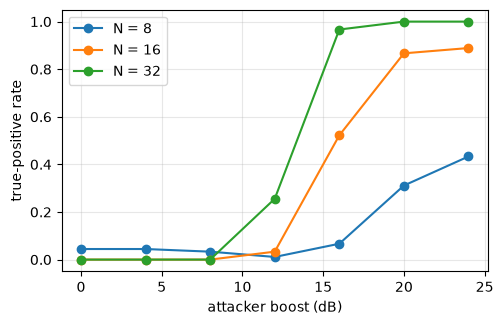

In [7]:
from aircompkit.defense.evaluate import detection_sweep
from aircompkit.learning import GradientBank

bank = GradientBank()
train(ac.Scenario(devices={"name": "fixed", "K": 24}, symbols="real"),
      FederatedConfig(dataset=data, rounds=6, record_bank=[1, 3, 5], clip=0.2, aggregation="ideal",
                      model={"name": "mlp", "hidden": [16]}), bank=bank)
boosts = [0, 4, 8, 12, 16, 20, 24]
fig, ax = plt.subplots(figsize=(5.5, 3.4))
for N in (8, 16, 32):
    scN = sc.replace(devices={"name": "fixed", "K": 24}, channel={"name": "rayleigh", "n_rx": N},
                     noise_var=10 ** -0.5)
    tpr = [detection_sweep(scN, bank.updates, {"name": "sign_flip", "boost_db": float(b)}, 3,
                           MatchedFilterNulling(), trials=30, clip=0.2)["tpr"] for b in boosts]
    ax.plot(boosts, tpr, "o-", label=f"N = {N}")
ax.set_xlabel("attacker boost (dB)"); ax.set_ylabel("true-positive rate"); ax.grid(alpha=0.3); ax.legend()
plt.show()

In a package of your own, import the module that defines the components before building
scenarios (the `@register` decorator runs on import). `aircompkit list` shows everything
registered. Next: [reproductions and benchmarks](06_reproductions_and_benchmarks.ipynb).